<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s <i>Girl with a pearl earing</i>: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#89AC76;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#89AC76;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#89AC76;">Table of Contents</span>


[ADICIONAR!!]

# <span id="chapter1" style="color:#89AC76;">1. Imports</span>

<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), "scripts"))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from functools import partial # pass a pre-applied selector via functools.partial.
from copy import deepcopy

from scripts.triangle_sol import TriangleSolution, AdaptiveMutationRateTriangleSolution
from scripts.ga import genetic_algorithm
from scripts.ga__2 import genetic_algorithm_vermeer
from scripts.ga_utils import get_fitness
from scripts.experiments import plot_fitness_history
from operators import (
    # selection
    roulette_wheel_selection,
    rank_based_selection,
    tournament_selection,
    # crossover
    one_point_crossover,
    two_point_crossover,
    uniform_crossover,
    geometric_crossover,
    # mutation
    triangle_gaussian_mutation,
    triangle_gaussian_color_mutation,
    triangle_gaussian_vertex_mutation,
    triangle_reset_gene_mutation,
    triangle_reset_mutation,
    triangle_layer_swap_mutation,
    geometric_mutation,
    # fitness sharing
    representation_vectors,
    sharing_function,
    compute_counts,
    apply_fitness_sharing, 
    fitness_sharing_selection, 
    measure_diversity,
)
from scripts.statistical_comparison import (
    run_ga_statistical_comparison,
    plot_statistical_comparison,
    run_statistical_test,
    save_statistical_results,
    load_statistical_results,
    plot_statistical_comparison_interactive
)

# <span id="chapter2" style="color:#89AC76;">2. Target Image Loading &amp; Inspection</span>

<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

Image size  : 300 x 400 px
Array shape : (400, 300, 4)


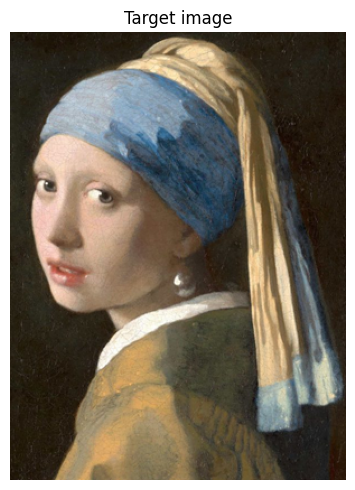

In [2]:
IMG_PATH = "project_info/girl_pearl_earing.png"

target_img = Image.open(IMG_PATH).convert("RGBA")
target_arr = np.array(target_img, dtype=np.float32)

IMG_WIDTH, IMG_HEIGHT = target_img.size   # (width, height) from PIL

print(f"Image size  : {IMG_WIDTH} x {IMG_HEIGHT} px")
print(f"Array shape : {target_arr.shape}")

# Pass the target to TriangleSolution so every instance uses it automatically
TriangleSolution.target_array = target_arr

plt.figure(figsize=(4, 5))
plt.imshow(target_arr / 255)
plt.title("Target image")
plt.axis("off")
plt.tight_layout()
plt.show()

# <span id="chapter3" style="color:#89AC76;">3. Solution Representation</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

### Representation - How the solution is encoded

Each individual in the population encodes a candidate image as an ordered sequence of **100 triangles**, drawn sequentially onto a 300×400 canvas — later triangles occlude earlier ones. Each triangle is represented by **10 real-valued genes**.

```
[ x1, y1, x2, y2, x3, y3, Red, Green, Blue, Alpha]
```


| Gene(s) | Variable | Domain |
|---|---|---|
| x₁, y₁, x₂, y₂, x₃, y₃ | Vertex coordinates | [0, 1] (normalised) |
| R, G, B | Fill colour | [0, 255] |
| A | Opacity | [0, 255] |

### Fitness - measurement of quality of the solution
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 4} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$

where $W=300$, $H=400$, and $C=4$ (RGBA channels)

In [4]:
sol = TriangleSolution()

In [5]:
sol = TriangleSolution()
sol.representation

array([229., 371.,  92., 347., 115., 297., 126.,  94., 218., 250., 101.,
        51.,   7.,  21., 201., 254., 123.,  38., 165., 226.,  86., 262.,
        96.,  29., 132.,  49.,  30.,  63., 198.,  95., 128., 386., 241.,
       389.,  18., 108., 148., 144., 223., 194., 276., 214.,  77.,  78.,
       149., 145.,   7., 244.,  74.,  81., 132., 230., 141., 222.,  51.,
       167., 101.,  55.,  64.,  91.,  44., 323., 270., 360.,  95., 112.,
       240.,  75., 182.,  94., 176., 153., 241., 177., 294., 319., 157.,
       213., 205., 198., 229., 130., 214.,  60., 118.,  66., 133.,  57.,
       196.,  14.,  18.,  59., 211., 244.,  25., 163.,  89.,  77.,  92.,
        84., 125., 264.,  98., 125.,  43.,  70., 169.,  92., 182., 174.,
        89., 101.,  16., 152.,  48.,  37., 164.,   8., 197.,   8.,  45.,
       386., 119., 279.,   6., 240., 139., 163.,  95., 228., 115., 245.,
       215., 149., 158.,  22.,   9., 105.,  86., 110., 251., 232., 212.,
       348.,  76., 358.,  43., 245., 150.,  27.,  6

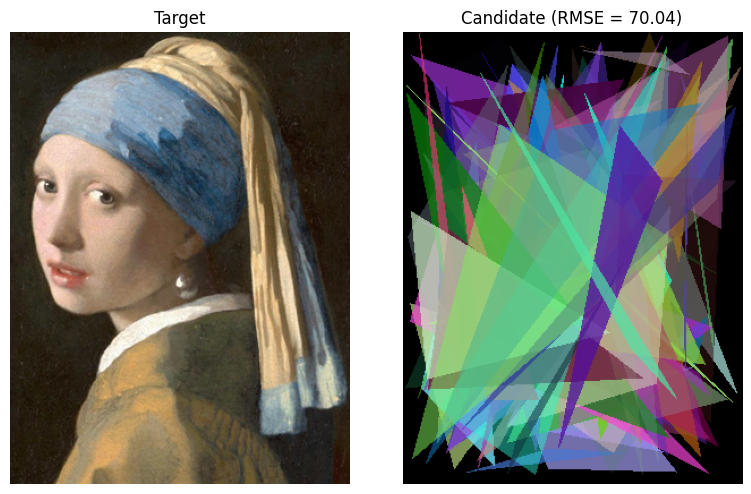

In [6]:
sol.show()

The output generated is a **single random individual**.

# <span id="chapter4" style="color:#89AC76;">4. Baseline GA Run</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

A single run with sensible defaults to confirm everything works end-to-end.

In [3]:
best_sol, history, avg_history = genetic_algorithm(
    population_size = 50,
    n_generations = 200,
    selection_function = tournament_selection,
    crossover_function = one_point_crossover,
    mutation_function = triangle_gaussian_mutation,
    crossover_rate = 0.9,
    mutation_rate = 0.02,
    mutation_rate_decay = None,
    elitism_n = 2,
    n_jobs = -1,
    verbose = True,
    verbose_every = 25
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 59.6626 | avg RMSE: 65.0064 | mut rate: 0.02000
Gen   25 | best RMSE: 52.9621 | avg RMSE: 53.4086 | mut rate: 0.02000
Gen   50 | best RMSE: 50.4394 | avg RMSE: 50.7068 | mut rate: 0.02000
Gen   75 | best RMSE: 47.5115 | avg RMSE: 47.8363 | mut rate: 0.02000
Gen  100 | best RMSE: 45.7102 | avg RMSE: 45.9732 | mut rate: 0.02000
Gen  125 | best RMSE: 44.5521 | avg RMSE: 44.7222 | mut rate: 0.02000
Gen  150 | best RMSE: 43.3007 | avg RMSE: 43.5274 | mut rate: 0.02000
Gen  175 | best RMSE: 42.0503 | avg RMSE: 42.3380 | mut rate: 0.02000
Gen  199 | best RMSE: 41.2623 | avg RMSE: 41.4657 | mut rate: 0.02000

Finished. Best RMSE: 41.2623
Best RMSE : 41.2623


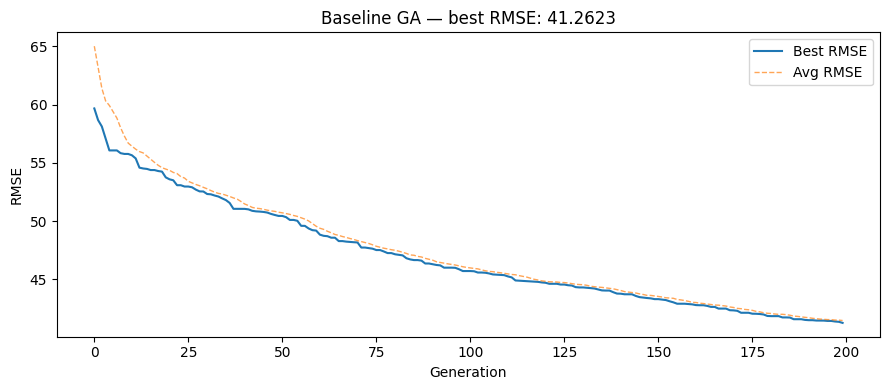

In [4]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {history[-1]:.4f}",
)

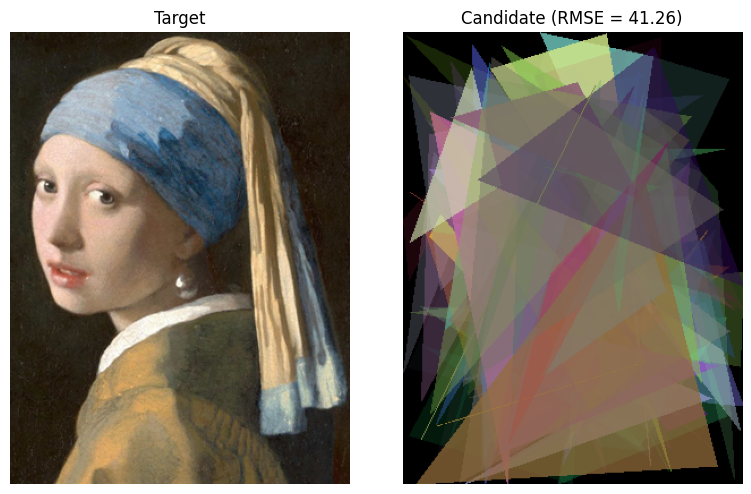

In [5]:
best_sol.show()

# <span id="chapter5" style="color:#89AC76;">5. Statistical Tests</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

This section addresses the selected additional challenge: evaluating how different GA components affect the quality of the final image. Since genetic algorithms are stochastic, each configuration is evaluated over multiple independent runs instead of relying on a single execution.

For each run, we store the best RMSE obtained after every generation. The resulting histories are summarized with:

- **ABF (Average Best Fitness):** average best RMSE across independent runs.
- **MBF (Median Best Fitness):** median best RMSE across independent runs, which is less sensitive to outlier runs.
- **Standard-deviation bands:** variation around the ABF curve, used to visually inspect stability.

The plots are used as an initial comparison, but close decisions are based on statistical tests applied to the final best RMSE values of each run. We first apply the Shapiro-Wilk test to check whether each sample is compatible with normality. If both samples are approximately normal, we use Welch's t-test. If at least one sample is not normal, we use the Mann-Whitney U test, also known as the Wilcoxon rank-sum test for independent samples. All tests use a significance level of **alpha = 0.05**.

For selection, crossover, mutation, mutation-rate, and elitism comparisons, the population size and number of generations are kept fixed, so curves can be compared by generation. For population-size experiments this is not enough, because larger populations perform more fitness evaluations per generation. Therefore, population-size results should be plotted against **cumulative fitness evaluations** under an equal evaluation budget.

## <span id="chapter5.1." style="color:#89AC76;">5.1 Selection</span>

try here all of the selection operators and do statistical tests to compare between them

to choose the size of the tournament selection, we need to take into account the size of the population and what is the resulting selection pressure, so that we can scale up the size of the population at the final run

In [33]:
selection_statistical_comparison = run_ga_statistical_comparison(
    "selection_function",
    [
        roulette_wheel_selection,
        rank_based_selection,
        tournament_selection, # default tournament size is 2, # with a population of size 200, this is a selection pressure of 1%
        lambda p: tournament_selection(p, tournament_size=3), # with a population of size 200, this is a selection pressure of 1.5%
        lambda p: tournament_selection(p, tournament_size=5), # with a population of size 200, this is a selection pressure of 2.5%
        lambda p: tournament_selection(p, tournament_size=10), # with a population of size 200, this is a selection pressure of 5%
    ]
)


Starting statistical comparison: 180 GA runs, 36,000 total generations



Progress: 100%|██████████| 36000/36000 [38:17<00:00, 15.67 gen/s]


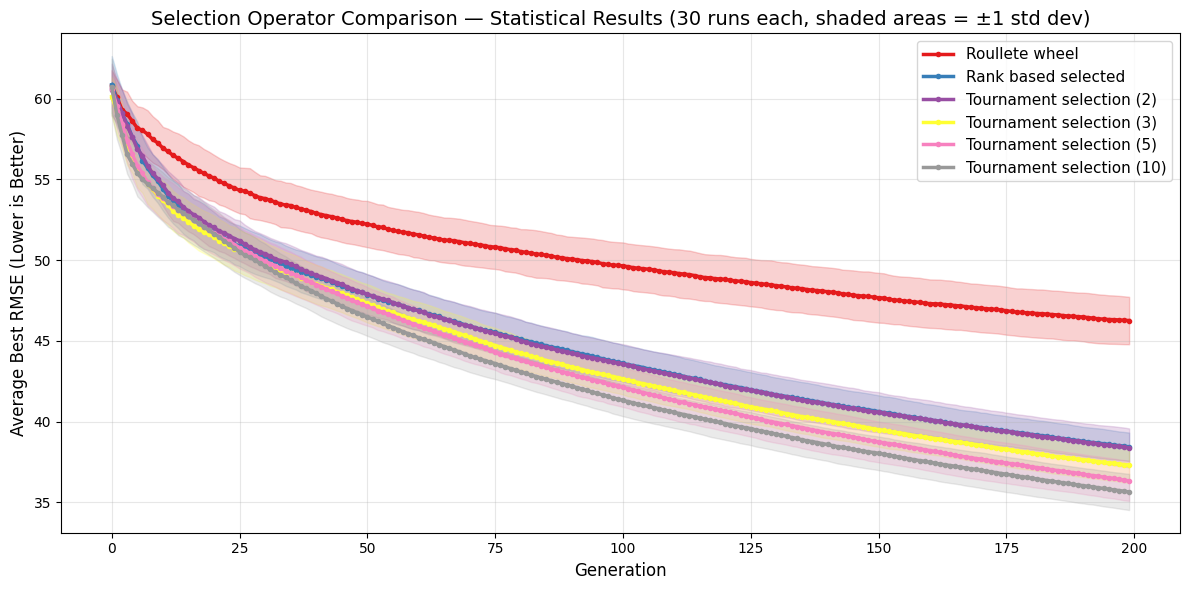

In [34]:
selection_functions = [
    "Roullete wheel",
    "Rank based selected",
    "Tournament selection (2)",
    "Tournament selection (3)",
    "Tournament selection (5)",
    "Tournament selection (10)"
]

plot_statistical_comparison(
    selection_statistical_comparison,
    labels=selection_functions,
    title="Selection Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

based on the results from this statistical comparison, let's try even lower selection pressures in tournament selection

In [10]:
selection_statistical_comparison2 = run_ga_statistical_comparison(
    "selection_function",
    [
        lambda p: tournament_selection(p, tournament_size=10), # with a population of size 200, this is a selection pressure of 5%
        lambda p: tournament_selection(p, tournament_size=15), # with a population of size 200, this is a selection pressure of 7.5%
        lambda p: tournament_selection(p, tournament_size=20), # with a population of size 200, this is a selection pressure of 10%
        lambda p: tournament_selection(p, tournament_size=30), # with a population of size 200, this is a selection pressure of 15%
    ]
)


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [25:55<00:00, 15.42 gen/s]


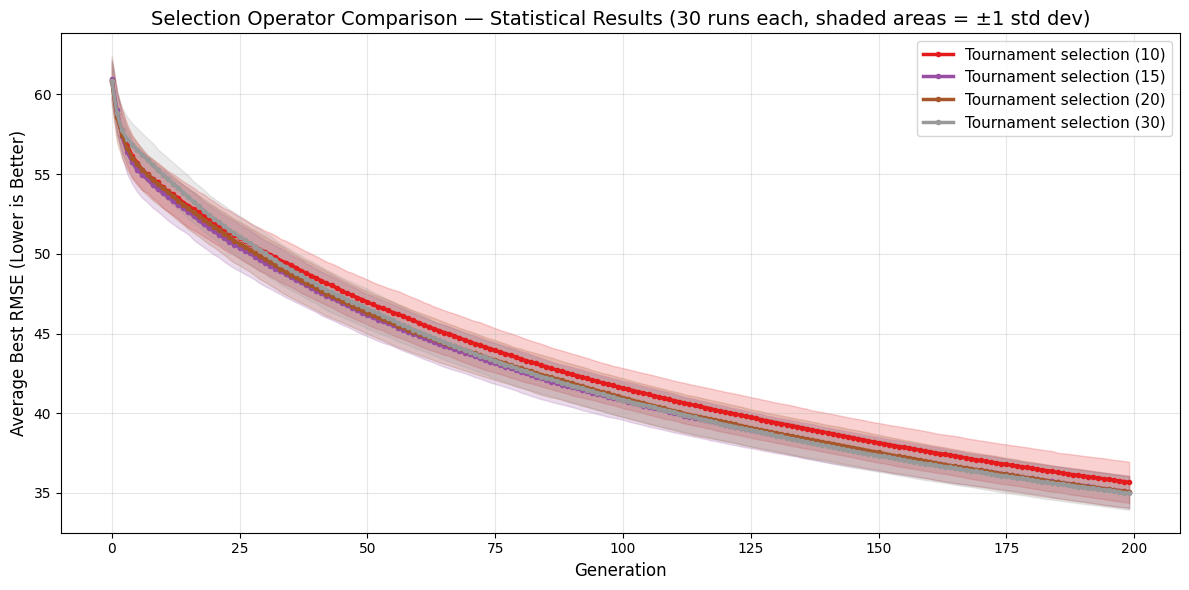

In [11]:
selection_functions = [
    "Tournament selection (10)",
    "Tournament selection (15)",
    "Tournament selection (20)",
    "Tournament selection (30)",
]

plot_statistical_comparison(
    selection_statistical_comparison2,
    labels=selection_functions,
    title="Selection Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

All of the values seem to be statistically equivalent, with all of them being really close together and inside the standard deviations of eachother

we should now do statistical tests to choose the best option

## <span id="chapter5.2" style="color:#89AC76;">5.2. Crossover</span>

try here all of the crossover operators and do statistical tests to compare between them

In [3]:
crossover_statistical_comparison = run_ga_statistical_comparison(
    "crossover_function",
    [
        one_point_crossover,
        two_point_crossover,
        uniform_crossover,
        geometric_crossover
    ]
)


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [27:56<00:00, 14.31 gen/s]


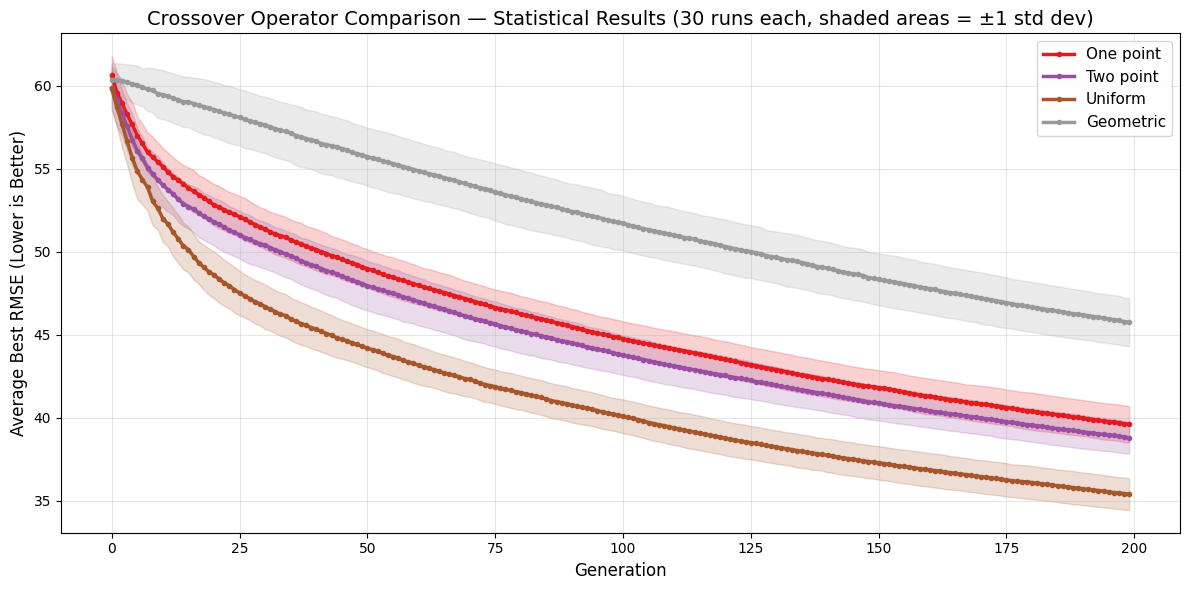

In [4]:
crossover_functions = [
    "One point",
    "Two point",
    "Uniform",
    "Geometric"
]

plot_statistical_comparison(
    crossover_statistical_comparison,
    labels=crossover_functions,
    title="Crossover Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

preciso de corrigir o geometric crossover para dar apenas um offspring

In [5]:
run_statistical_test(
    crossover_statistical_comparison[one_point_crossover]["best_per_run"],
    crossover_statistical_comparison[uniform_crossover]["best_per_run"],
    name_a="One point",
    name_b="Uniform",
    paired=False
)

One point normality p-value: 0.5982
Uniform normality p-value: 0.3007

Welch t-test
p-value: 0.0000

One point mean final RMSE: 39.6114
Uniform mean final RMSE: 35.4099
Difference is statistically significant.


In [6]:
run_statistical_test(
    crossover_statistical_comparison[two_point_crossover]["best_per_run"],
    crossover_statistical_comparison[uniform_crossover]["best_per_run"],
    name_a="Two point",
    name_b="Uniform",
    paired=False
)

Two point normality p-value: 0.0644
Uniform normality p-value: 0.3007

Welch t-test
p-value: 0.0000

Two point mean final RMSE: 38.7940
Uniform mean final RMSE: 35.4099
Difference is statistically significant.


now we test for the best crossover rate

In [10]:
crossover_rate_statistical_comparison = run_ga_statistical_comparison(
    "crossover_rate",
    [
        0.90,
        0.80,
        0.70,
        0.50,
        0.30
    ],
    fixed_params={
        "crossover_function": uniform_crossover
    }
)


Starting statistical comparison: 150 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [35:13<00:00, 709.80 evaluation/s]


In [11]:
save_statistical_results(
    crossover_rate_statistical_comparison,
    "results/crossover_rate_statistical_comparison.pkl"
)

In [ ]:
crossover_rate_statistical_comparison = load_statistical_results("results/crossover_rate_statistical_comparison.pkl")

In [12]:
crossover_rates = [
    "0.90",
    "0.80",
    "0.70",
    "0.50",
    "0.30"
]

plot_statistical_comparison_interactive(
    crossover_rate_statistical_comparison,
    labels=crossover_rates,
    title="Crossover Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

## <span id="chapter5.3" style="color:#89AC76;">5.3. Mutation</span>

### <span id="chapter5.3.1" style="color:#89AC76;">5.3.1. Mutation operator</span>

In [ ]:
# mutation_statistical_comparison = run_ga_statistical_comparison(
#     "mutation_function",
#     [
#         triangle_gaussian_mutation,
#         triangle_gaussian_color_mutation,
#         triangle_gaussian_vertex_mutation,
#         triangle_reset_gene_mutation,
#         triangle_reset_mutation,
#         triangle_layer_swap_mutation,
#         geometric_mutation
#     ]
# )


Starting statistical comparison: 210 GA runs, 2,100,000 total evaluations



Progress: 100%|██████████| 2100000/2100000 [44:57<00:00, 778.44 evaluation/s]


In [ ]:
# save_statistical_results(
#     mutation_statistical_comparison,
#     "results/mutation_statistical_comparison.pkl"
# )

In [ ]:
mutation_statistical_comparison = load_statistical_results("results/mutation_statistical_comparison.pkl")

In [9]:
mutation_modes = [
    "Gaussian (full)",
    "Gaussian (color)",
    "Gaussian (vertex)",
    "Reset (per-gene)",
    "Reset (per-triangle)",
    "Layer swap",
    "Geometric"
]

plot_statistical_comparison_interactive(
    mutation_statistical_comparison,
    labels=mutation_modes,
    title="Mutation Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

### <span id="chapter5.3.2" style="color:#89AC76;">5.3.2. Mutation rate</span>

Now we need to select the best mutation rate

In [ ]:
# mutation_rate_statistical_comparison = run_ga_statistical_comparison(
#     "mutation_rate",
#     [
#         0.50,
#         0.20,
#         0.10,
#         0.05,
#         0.02,
#         0.01
#     ]
# )


Starting statistical comparison: 180 GA runs, 36,000 total generations



Progress: 100%|██████████| 36000/36000 [45:15<00:00, 13.26 gen/s] 


In [ ]:
# save_statistical_results(
#     mutation_rate_statistical_comparison,
#     "results/mutation_rate_statistical_comparison.pkl"
# )

In [3]:
mutation_rate_statistical_comparison = load_statistical_results("results/mutation_rate_statistical_comparison.pkl")

In [7]:
mutation_rates = [
    "0.50",
    "0.20",
    "0.10",
    "0.05",
    "0.02",
    "0.01"
]

plot_statistical_comparison_interactive(
    mutation_rate_statistical_comparison,
    labels=mutation_rates,
    title="Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [9]:
run_statistical_test(
    mutation_rate_statistical_comparison[0.01]["best_per_run"],
    mutation_rate_statistical_comparison[0.02]["best_per_run"],
    name_a="0.01",
    name_b="0.02",
    paired=False
)

0.01 normality p-value: 0.2514
0.02 normality p-value: 0.4021

Welch t-test
p-value: 0.0013

0.01 mean final RMSE: 40.2189
0.02 mean final RMSE: 39.0638
Difference is statistically significant.


In [11]:
run_statistical_test(
    mutation_rate_statistical_comparison[0.02]["best_per_run"],
    mutation_rate_statistical_comparison[0.05]["best_per_run"],
    name_a="0.02",
    name_b="0.05",
    paired=False
)

0.02 normality p-value: 0.4021
0.05 normality p-value: 0.9225

Welch t-test
p-value: 0.0000

0.02 mean final RMSE: 39.0638
0.05 mean final RMSE: 37.0871
Difference is statistically significant.


In [22]:
run_statistical_test(
    mutation_rate_statistical_comparison[0.05]["best_per_run"],
    mutation_rate_statistical_comparison[0.10]["best_per_run"],
    name_a="0.05",
    name_b="0.10",
    paired=False
)

0.05 normality p-value: 0.9225
0.10 normality p-value: 0.0003

Mann-Whitney U / Wilcoxon rank-sum test
p-value: 0.0007

0.05 mean final RMSE: 37.0871
0.10 mean final RMSE: 36.1952
Difference is statistically significant.


### <span id="chapter5.3.3" style="color:#89AC76;">5.3.3. Gaussian mutation sigma</span>

gaussian mutation has two additional parameters we can tune, sigma_vertex and sigma_color

#### Sigma vertex

In [ ]:
# sigma_vertex_statistical_comparison = run_ga_statistical_comparison(
#     "sigma_vertex",
#     [
#         2,
#         5,
#         10,
#         20,
#         50
#     ]
# )


Starting statistical comparison: 150 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [32:31<00:00, 768.82 evaluation/s]


In [ ]:
# save_statistical_results(
#     sigma_vertex_statistical_comparison,
#     "results/sigma_vertex_statistical_comparison.pkl"
# )

In [6]:
sigma_vertex_statistical_comparison = load_statistical_results("results/sigma_vertex_statistical_comparison.pkl")

In [7]:
sigma_vertex = [
    "2",
    "5",
    "10",
    "20",
    "50"
]

plot_statistical_comparison_interactive(
    sigma_vertex_statistical_comparison,
    labels=sigma_vertex,
    title="Mutation Sigma Vertex Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [8]:
run_statistical_test(
    sigma_vertex_statistical_comparison[2]["best_per_run"],
    sigma_vertex_statistical_comparison[5]["best_per_run"],
    "2",
    "5",
    paired=False
)

2 normality p-value: 0.2538
5 normality p-value: 0.4879

Welch t-test
p-value: 0.9204

2 mean final RMSE: 39.5895
5 mean final RMSE: 39.6208
No statistically significant difference detected.


#### Sigma color

In [6]:
sigma_color_statistical_comparison = run_ga_statistical_comparison(
    "sigma_color",
    [
        2,
        5,
        10,
        20,
        50
    ]
)


Starting statistical comparison: 150 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [38:01<00:00, 657.33 evaluation/s]


In [7]:
save_statistical_results(
    sigma_color_statistical_comparison,
    "results/sigma_color_statistical_comparison.pkl"
)

In [ ]:
sigma_color_statistical_comparison = load_statistical_results("results/sigma_color_statistical_comparison.pkl")

In [8]:
sigma_color = [
    "2",
    "5",
    "10",
    "20",
    "50"
]

plot_statistical_comparison_interactive(
    sigma_color_statistical_comparison,
    labels=sigma_color,
    title="Mutation Sigma Color Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

all of them seem equivalent

In [10]:
run_statistical_test(
    sigma_color_statistical_comparison[2]["best_per_run"],
    sigma_color_statistical_comparison[10]["best_per_run"],
    "2",
    "10",
    paired=False
)

2 normality p-value: 0.2489
10 normality p-value: 0.2096

Welch t-test
p-value: 0.5744

2 mean final RMSE: 39.0989
10 mean final RMSE: 39.2479
No statistically significant difference detected.


### <span id="chapter5.3.4" style="color:#89AC76;">5.3.4. Adaptive mutation rate</span>

Now we will test strategies for adapting mutation rates:
- Mutation rate decay
- Self-adaptive mutation rate (gene)

#### Mutation rate decay

In [3]:
mutation_rate_decay_statistical_comparison = run_ga_statistical_comparison(
    "mutation_rate_decay",
    [
        None,
        0.1,
        0.01,
        0.001,
        0.0001,
        0.00001
    ]
)


Starting statistical comparison: 180 GA runs, 36,000 total generations



Progress: 100%|██████████| 36000/36000 [38:20<00:00, 15.65 gen/s] 


In [ ]:
save_statistical_results(
    mutation_rate_decay_statistical_comparison,
    "results/mutation_rate_decay_statistical_comparison.pkl"
)

In [ ]:
sigma_color_statistical_comparison = load_statistical_results("results/mutation_rate_decay_statistical_comparison.pkl")

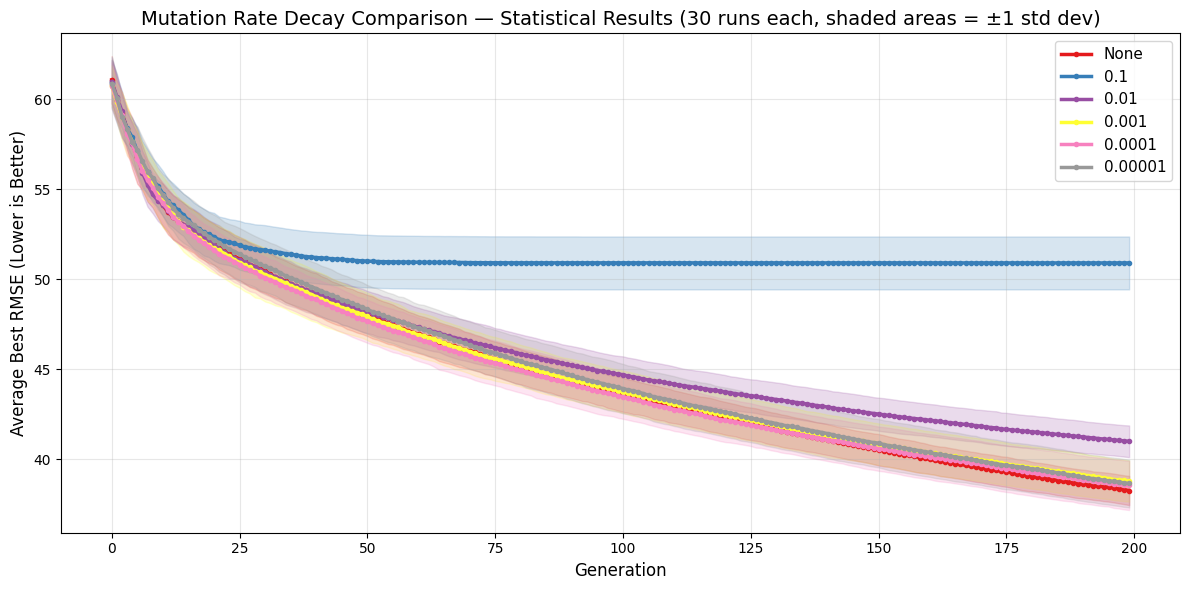

In [ ]:
mutation_rate_decay_values = [
    "None",
    "0.1",
    "0.01",
    "0.001",
    "0.0001",
    "0.00001"
]

plot_statistical_comparison_interactive(
    mutation_rate_decay_statistical_comparison,
    labels=mutation_rate_decay_values,
    title="Mutation Rate Decay Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

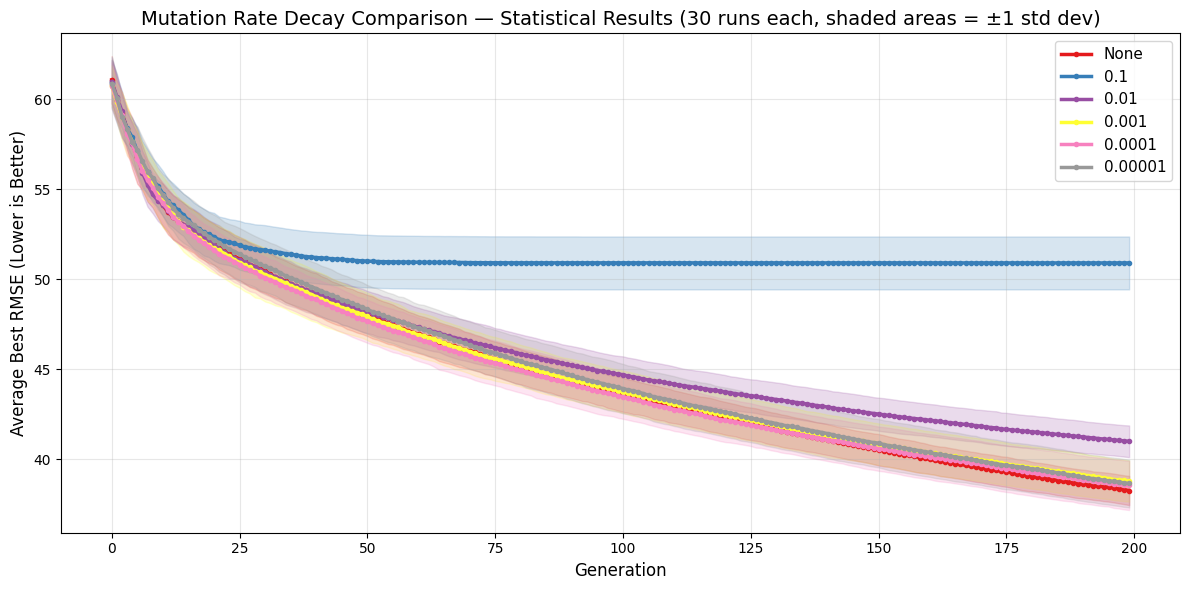

In [ ]:
mutation_rate_decay_values = [
    "None",
    "0.1",
    "0.01",
    "0.001",
    "0.0001",
    "0.00001"
]

plot_statistical_comparison(
    mutation_rate_decay_statistical_comparison,
    labels=mutation_rate_decay_values,
    title="Mutation Rate Decay Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

#### Adaptive mutation rate

In [ ]:
# adaptive_mutation_rate_statistical_comparison = run_ga_statistical_comparison(
#     "solution_class",
#     [
#         TriangleSolution,
#         AdaptiveMutationRateTriangleSolution
#     ],
#     eval_budget=25_000 # 50 individuals x 500 generations
# )


Starting statistical comparison: 60 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [35:43<00:00, 699.63 evaluation/s]


In [ ]:
# save_statistical_results(
#     adaptive_mutation_rate_statistical_comparison,
#     "results/adaptive_mutation_rate_statistical_comparison.pkl"
# )

In [ ]:
adaptive_mutation_rate_statistical_comparison = load_statistical_results("results/adaptive_mutation_rate_statistical_comparison.pkl")

In [ ]:
mutation_rate_strategy = [
    "Static mutation rate",
    "Self-adaptive mutation rate"
]

plot_statistical_comparison_interactive(
    adaptive_mutation_rate_statistical_comparison,
    labels=mutation_rate_strategy,
    title="Adptive Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [ ]:
run_statistical_test(
    adaptive_mutation_rate_statistical_comparison[TriangleSolution]["best_per_run"],
    sigma_color_statistical_comparison[AdaptiveMutationRateTriangleSolution]["best_per_run"],
    "Static mutation rate",
    "Self-adaptive mutation rate",
    paired=False
)

## <span id="chapter5.4" style="color:#89AC76;">5.4. Elitism</span>

In [ ]:
# elitism_n_statistical_comparison = run_ga_statistical_comparison(
#     "elitism_n",
#     [
#         2,
#         5,
#         10,
#         20
#     ]
# )


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [21:43<00:00, 18.42 gen/s]


In [ ]:
# save_statistical_results(
#     elitism_n_statistical_comparison,
#     "results/elitism_n_statistical_comparison.pkl"
# )

In [15]:
elitism_n_statistical_comparison = load_statistical_results("results/elitism_n_statistical_comparison.pkl")

In [16]:
elitism_n = [
    "2",
    "5",
    "10",
    "20"
]

plot_statistical_comparison_interactive(
    elitism_n_statistical_comparison,
    labels=elitism_n,
    title="Elitism Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

add statistical tests

## <span id="chapter5.5" style="color:#89AC76;">5.5. Population size</span>

this test is not fair, as the bigger the population, the more evaluations were done

but it may be useful to check which is the biggest population size that still makes sense to use while not being too slow

In [17]:
population_size_statistical_comparison = run_ga_statistical_comparison(
    "population_size",
    [
        200,
        400,
        800,
        1500
    ]
)


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [6:07:31<00:00,  1.09 gen/s]  


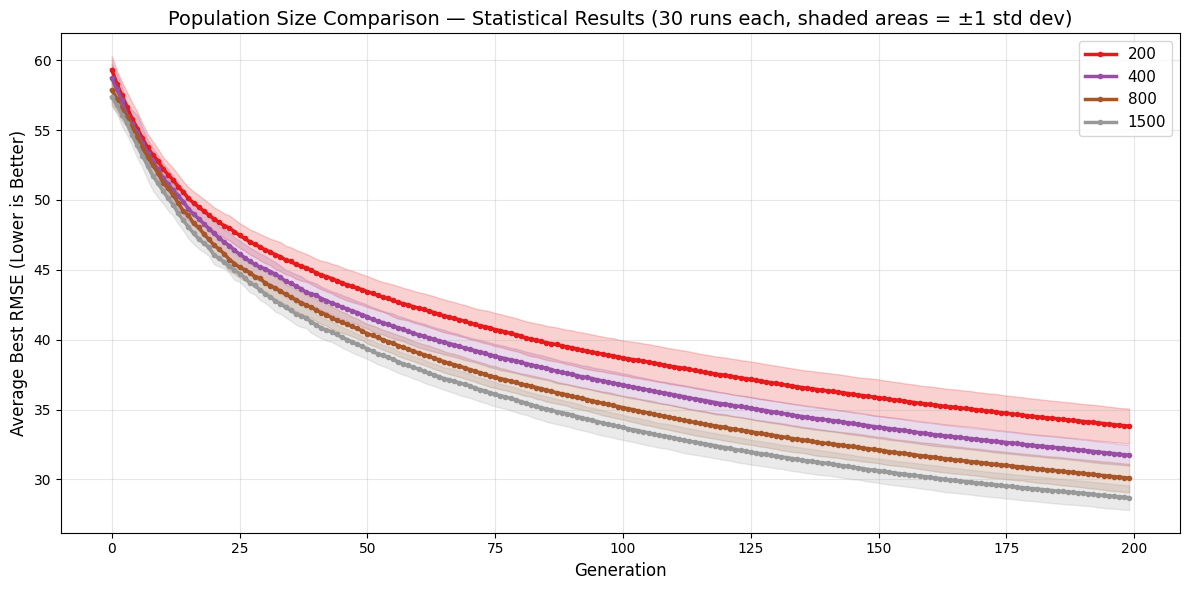

In [18]:
population_sizes = [
    "200",
    "400",
    "800",
    "1500"
]

plot_statistical_comparison(
    population_size_statistical_comparison,
    labels=population_sizes,
    title="Population Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [ ]:
# population_size_statistical_comparison = run_ga_statistical_comparison(
#     "population_size",
#     [
#         200,
#         400,
#         800,
#         1500
#     ],
#     eval_budget=12_000 # 12 000 is the least common multiple between all of the options
# )


Starting statistical comparison: 120 GA runs, 1,440,000 total evaluations



Progress: 100%|██████████| 1440000/1440000 [35:51<00:00, 669.25 evaluation/s]


In [ ]:
# save_statistical_results(
#     population_size_statistical_comparison,
#     "results/population_size_statistical_comparison.pkl"
# )

In [ ]:
population_size_statistical_comparison = load_statistical_results("results/population_size_statistical_comparison.pkl")

In [11]:
population_sizes = [
    "200",
    "400",
    "800",
    "1500"
]

plot_statistical_comparison_interactive(
    population_size_statistical_comparison,
    labels=population_sizes,
    title="Population Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

add statistical tests

# <span id="chapter6" style="color:#89AC76;">6. Final GA Run </span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

In [19]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=800,
    n_generations=2000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 58.2414 | avg RMSE: 68.5261 | mut rate: 0.01000
Gen   50 | best RMSE: 32.6811 | avg RMSE: 33.0376 | mut rate: 0.01000
Gen  100 | best RMSE: 28.4080 | avg RMSE: 28.5723 | mut rate: 0.01000
Gen  150 | best RMSE: 26.3321 | avg RMSE: 26.4435 | mut rate: 0.01000
Gen  200 | best RMSE: 25.0181 | avg RMSE: 25.1214 | mut rate: 0.01000
Gen  250 | best RMSE: 24.0273 | avg RMSE: 24.1036 | mut rate: 0.01000
Gen  300 | best RMSE: 23.2857 | avg RMSE: 23.3618 | mut rate: 0.01000
Gen  350 | best RMSE: 22.6252 | avg RMSE: 22.7005 | mut rate: 0.01000
Gen  400 | best RMSE: 22.1101 | avg RMSE: 22.1982 | mut rate: 0.01000
Gen  450 | best RMSE: 21.7268 | avg RMSE: 21.8015 | mut rate: 0.01000
Gen  500 | best RMSE: 21.3595 | avg RMSE: 21.4520 | mut rate: 0.01000
Gen  550 | best RMSE: 21.1173 | avg RMSE: 21.2031 | mut rate: 0.01000
Gen  600 | best RMSE: 20.7939 | avg RMSE: 20.8765 | mut rate: 0.01000
Gen  650 | best RMSE: 20.5164 | avg RMSE: 20.6087 | mut rate: 0.01000
Gen  700 | best RMSE

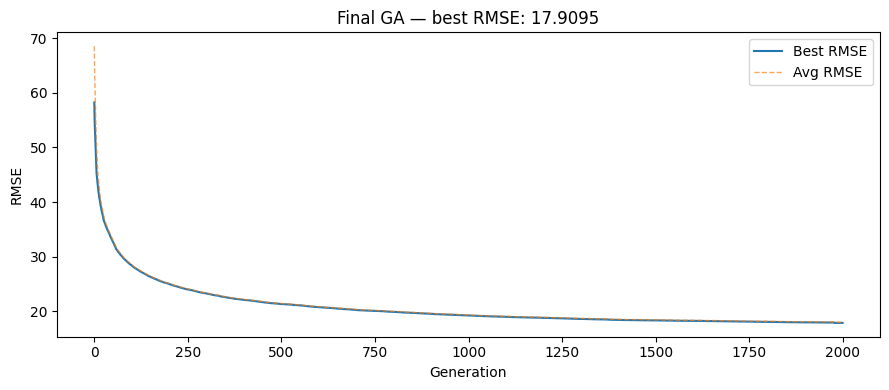

In [22]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Final GA — best RMSE: {history[-1]:.4f}",
)

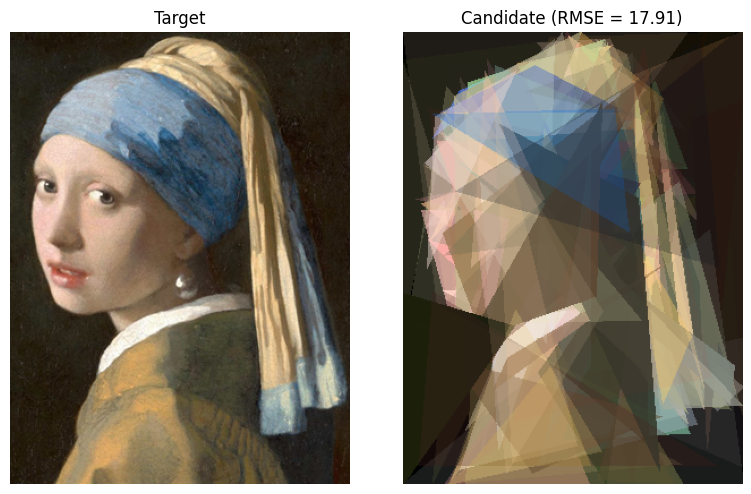

In [20]:
best_sol.show()

# <span id="chapter7" style="color:#89AC76;">7. Hill Climbing for Local Search</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

-- ainda não foi testado --- em desenvolvimento

# <span id="chapter8" style="color:#89AC76;">8. Best Candidate vs. Target </span>

o que fazer aqui? talvez esta secção não faça muito sentido

# <span id="chapter9" style="color:#89AC76;">9. Save Best Result</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

In [21]:
out_path = "best_result.png"
best_sol.get_image().save(out_path)
print(f"Saved best candidate to: {out_path}")

Saved best candidate to: best_result.png
